# Qwen-27B Expanded Cross-Context Source Readiness

The first correct-source distance-rescue pilot was technically valid but could freeze only three independent target/source bundles.

[实验设置与运行说明](../../../docs/experiment_notes/10_exploratory_composition_and_gating/675ebc1ad1b0b465.md)


In [1]:
# Run once. Every later code cell reports both cell and inner-loop progress.
import re
import threading
import time
from IPython.core.magic import register_cell_magic
from tqdm.auto import tqdm

_SETUP_PROGRESS = tqdm(total=1, desc='Initialize progress display', unit='cell')
_ACTIVE_CELL_PROGRESS = None

def cell_stage(message):
    if _ACTIVE_CELL_PROGRESS is not None:
        _ACTIVE_CELL_PROGRESS['stage'] = str(message)
        elapsed = time.monotonic() - _ACTIVE_CELL_PROGRESS['started']
        _ACTIVE_CELL_PROGRESS['bar'].set_postfix_str(
            f"{message} | elapsed {elapsed:.0f}s", refresh=True
        )

@register_cell_magic
def cell_progress(line, cell):
    global _ACTIVE_CELL_PROGRESS
    specification = line.strip() or 'Cell progress'
    match = re.fullmatch(r'(\d+)/(\d+)\s+(.+)', specification)
    if match:
        current, total, label = int(match.group(1)), int(match.group(2)), match.group(3)
        initial = current - 1
    else:
        current, total, label, initial = 1, 1, specification, 0
    started = time.monotonic()
    bar = tqdm(
        total=total, initial=initial, desc=label, unit='cell',
        dynamic_ncols=True, leave=True,
    )
    state = {'bar': bar, 'started': started, 'stage': 'starting'}
    _ACTIVE_CELL_PROGRESS = state
    stopped = threading.Event()

    def heartbeat():
        while not stopped.wait(1.0):
            elapsed = time.monotonic() - started
            bar.set_postfix_str(
                f"{state['stage']} | elapsed {elapsed:.0f}s", refresh=True
            )

    worker = threading.Thread(target=heartbeat, daemon=True)
    worker.start()
    succeeded = False
    try:
        cell_stage('running')
        result = get_ipython().run_cell(cell)
        result.raise_error()
        succeeded = True
        return result.result
    finally:
        stopped.set()
        worker.join(timeout=2.0)
        elapsed = time.monotonic() - started
        if succeeded:
            bar.n = current
            bar.set_postfix_str(f"complete | elapsed {elapsed:.0f}s", refresh=True)
        else:
            bar.set_postfix_str(f"failed | elapsed {elapsed:.0f}s", refresh=True)
        bar.close()
        _ACTIVE_CELL_PROGRESS = None

_SETUP_PROGRESS.update(1)
_SETUP_PROGRESS.close()
print('Cell progress helper ready: 17 tracked cells.')


Initialize progress display:   0%|          | 0/1 [00:00<?, ?cell/s]

Cell progress helper ready: 17 tracked cells.


## 1. Behavior-only expanded support


In [2]:
%%cell_progress 1/15 Mount Drive and locate VisualTorque
cell_stage('Mounting Google Drive')
from google.colab import drive
drive.mount('/content/drive')

cell_stage('Locating VisualTorque project')
from pathlib import Path
PROJECT_CANDIDATES = (
    Path('/content/drive/MyDrive/VisualTorque'),
    Path('/content/drive/MyDrive/VisualTorque/VisualTorque'),
)
PROJECT_ROOT = next(
    (
        path for path in PROJECT_CANDIDATES
        if (path / 'toolkit' / 'pyproject.toml').is_file()
    ),
    None,
)
assert PROJECT_ROOT is not None, (
    'Could not find VisualTorque/toolkit/pyproject.toml on Drive.'
)
TOOLKIT_ROOT = PROJECT_ROOT / 'toolkit'
print('Project:', PROJECT_ROOT)


Mount Drive and locate VisualTorque:   0%|          | 0/15 [00:00<?, ?cell/s]

Mounted at /content/drive
Project: /content/drive/MyDrive/VisualTorque


In [3]:
%%cell_progress 2/15 Install and verify the multimodal environment
import importlib
import subprocess
import sys

cell_stage('Removing unused TorchAudio')
subprocess.run(
    [sys.executable, '-m', 'pip', 'uninstall', '-y', 'torchaudio'],
    check=False,
)
cell_stage('Installing pinned inference and analysis dependencies')
subprocess.check_call([
    sys.executable, '-m', 'pip', 'install', '-q', '-U',
    'transformers==5.14.0', 'accelerate>=1.10', 'sentencepiece',
    'protobuf', 'huggingface_hub>=0.34', 'tqdm>=4.66',
    'pandas>=2.2', 'matplotlib>=3.8', 'scikit-learn>=1.5',
])

cell_stage('Registering the live VisualTorque source tree')
SRC_ROOT = TOOLKIT_ROOT / 'src'
PACKAGE_ROOT = SRC_ROOT / 'visual_torque_toolkit'
assert (PACKAGE_ROOT / '__init__.py').is_file(), PACKAGE_ROOT
source_text = str(SRC_ROOT)
sys.path[:] = [entry for entry in sys.path if entry != source_text]
sys.path.insert(0, source_text)
for module_name in tuple(sys.modules):
    if (
        module_name == 'visual_torque_toolkit'
        or module_name.startswith('visual_torque_toolkit.')
    ):
        del sys.modules[module_name]
importlib.invalidate_caches()

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torchvision
import visual_torque_toolkit
from IPython.display import display
from transformers import AutoModelForMultimodalLM, AutoProcessor
from visual_torque_toolkit.behavior.adapter import HuggingFaceMultimodalAdapter

required_features = (
    '_template', '_to_device', '_candidate_plan', '_append_text_prefix',
)
assert all(
    hasattr(HuggingFaceMultimodalAdapter, name)
    for name in required_features
)
toolkit_path = Path(visual_torque_toolkit.__file__).resolve()
assert PACKAGE_ROOT.resolve() in toolkit_path.parents, toolkit_path
print('torch:', torch.__version__, '| CUDA:', torch.version.cuda)
print('torchvision:', torchvision.__version__)
print('Toolkit source:', toolkit_path)


Install and verify the multimodal environment:   7%|6         | 1/15 [00:00<?, ?cell/s]

torch: 2.11.0+cu128 | CUDA: 12.8
torchvision: 0.26.0+cu128
Toolkit source: /content/drive/MyDrive/VisualTorque/toolkit/src/visual_torque_toolkit/__init__.py


In [4]:
%%cell_progress 3/15 Verify GPU and Hugging Face access
cell_stage('Checking CUDA device')
assert torch.cuda.is_available(), 'Select an A100 GPU runtime.'
print(torch.cuda.get_device_name(0))
print('CUDA memory (GB):', round(
    torch.cuda.get_device_properties(0).total_memory / 2**30, 1
))

cell_stage('Authenticating with Hugging Face')
from google.colab import userdata
from huggingface_hub import login
try:
    token = userdata.get('HF_TOKEN')
    if token:
        login(token=token, add_to_git_credential=False)
        print('Hugging Face login complete.')
    else:
        print('HF_TOKEN is not set. Public checkpoints may still work.')
except Exception as exc:
    print('Hugging Face login skipped:', exc)


Verify GPU and Hugging Face access:  13%|#3        | 2/15 [00:00<?, ?cell/s]

NVIDIA RTX PRO 6000 Blackwell Server Edition
CUDA memory (GB): 95.0
Hugging Face login skipped: Secret HF_TOKEN does not exist.


In [5]:
%%cell_progress 4/15 Lock the expanded-source readiness protocol
cell_stage('Freezing target definition, source geometry, and readiness gates')
import hashlib
import json
from datetime import datetime, timezone

MODEL_ID = 'Qwen/Qwen3.5-27B'
MODEL_SLUG = 'Qwen__Qwen3.5-27B__373612cb'
MODEL_REVISION = '373612cb4f9288fcf550b526d86d85febedd9801'
MODEL_DTYPE = 'bfloat16'
DEVICE_MAP = 'auto'
EXPECTED_LAYER_COUNT = 64
SEED = 20261018

TARGET_BUNDLES = 12
MIN_BUNDLES = 8
MIN_PER_MAPPING = 2
MIN_PER_SIDE = 2
MAX_WEIGHT_DOSE_ERROR = 2
SOURCE_CANDIDATES_PER_TARGET = 24
MAPPING_VARIANTS = ('forward', 'reverse')

READINESS_ROOT = (
    PROJECT_ROOT / 'results'
    / 'qwen27b_competence_matched_clearance_readiness_v1'
)
CANDIDATE_PATH = READINESS_ROOT / 'model_blind_candidate_groups.jsonl'
PRIOR_SCREEN_PATH = READINESS_ROOT / 'behavior_screen_results.jsonl'
FLIPERROR_ROOT = (
    PROJECT_ROOT / 'results'
    / 'qwen27b_matched_clearance_fliperror_rescue_v2'
)
FLIPERROR_RUN_PATH = FLIPERROR_ROOT / 'RUN_COMPLETE.json'
PILOT_ROOT = (
    PROJECT_ROOT / 'results'
    / 'qwen27b_correctsource_distance_rescue_v1'
)
PILOT_RUN_PATH = PILOT_ROOT / 'RUN_COMPLETE.json'
PILOT_MANIFEST_PATH = PILOT_ROOT / 'frozen_confirmation_manifest.jsonl'
for required in (
    CANDIDATE_PATH, PRIOR_SCREEN_PATH, FLIPERROR_RUN_PATH,
    PILOT_RUN_PATH, PILOT_MANIFEST_PATH,
):
    assert required.is_file(), f'Missing prerequisite: {required}'

OUTPUT_ROOT = (
    PROJECT_ROOT / 'results'
    / 'qwen27b_expanded_crosscontext_source_readiness_v1'
)
TARGET_POOL_PATH = OUTPUT_ROOT / 'frozen_target_candidate_pool.jsonl'
SOURCE_POOL_PATH = OUTPUT_ROOT / 'full_scene_source_candidates.jsonl'
POOL_LOCK_PATH = OUTPUT_ROOT / 'candidate_pool_lock.json'
REQUEST_PATH = OUTPUT_ROOT / 'batch_one_requests.jsonl'
SCREEN_SHARD_DIR = OUTPUT_ROOT / 'screen_shards'
SCREEN_RESULT_PATH = OUTPUT_ROOT / 'batch_one_results.jsonl'
MANIFEST_PATH = OUTPUT_ROOT / 'expanded_confirmation_manifest.jsonl'
MANIFEST_LOCK_PATH = OUTPUT_ROOT / 'manifest_lock.json'
PROTOCOL_LOCK_PATH = OUTPUT_ROOT / 'frozen_readiness_protocol.json'
ANALYSIS_DIR = OUTPUT_ROOT / 'analysis'
FIGURE_DIR = ANALYSIS_DIR / 'figures'
for path in (OUTPUT_ROOT, SCREEN_SHARD_DIR, ANALYSIS_DIR, FIGURE_DIR):
    path.mkdir(parents=True, exist_ok=True)

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(chunk)
    return 'sha256:' + digest.hexdigest()

def read_jsonl(path):
    with Path(path).open('r', encoding='utf-8') as handle:
        return [json.loads(line) for line in handle if line.strip()]

def write_json_atomic(path, value):
    path = Path(path)
    temporary = path.with_suffix(path.suffix + '.tmp')
    temporary.write_text(
        json.dumps(value, indent=2, ensure_ascii=False) + '\n',
        encoding='utf-8',
    )
    temporary.replace(path)

def write_jsonl_atomic(path, rows):
    path = Path(path)
    temporary = path.with_suffix(path.suffix + '.tmp')
    with temporary.open('w', encoding='utf-8') as handle:
        for row in rows:
            handle.write(json.dumps(row, sort_keys=True) + '\n')
    temporary.replace(path)

def stable_key(value):
    return hashlib.sha256(f'{SEED}:{value!r}'.encode('utf-8')).hexdigest()

fliperror_run = json.loads(FLIPERROR_RUN_PATH.read_text(encoding='utf-8'))
assert fliperror_run['primary_decision'] == (
    'targeted_flip_error_route_confirmed_for_one_factor'
)
pilot_run = json.loads(PILOT_RUN_PATH.read_text(encoding='utf-8'))
assert pilot_run['primary_decision'] == (
    'insufficient_independent_cross_context_sources'
)

protocol_identity = {
    'schema_version': 'expanded-crosscontext-readiness-1.0',
    'analysis_status': 'behavior-only readiness; no activation capture',
    'model_id': MODEL_ID,
    'revision': MODEL_REVISION,
    'target_definition': (
        'distance-only outcome flip; target correct; hybrid repeats target '
        'answer under exact batch-one target mapping'
    ),
    'distance_source_definition': (
        'same-side exact distance change; different weight context; answer '
        'invariant and different from desired target answer'
    ),
    'weight_control_definition': (
        'same-side weight-only change; answer invariant and different from '
        'desired target answer; physical dose error minimized'
    ),
    'target_bundles': TARGET_BUNDLES,
    'minimum_bundles': MIN_BUNDLES,
    'minimum_per_mapping': MIN_PER_MAPPING,
    'minimum_per_side': MIN_PER_SIDE,
    'maximum_weight_dose_error': MAX_WEIGHT_DOSE_ERROR,
    'condition_batch_size': 1,
    'selection_may_use': ['scene geometry', 'natural endpoint behavior'],
    'selection_may_not_use': [
        'activations', 'layers', 'token regions', 'intervention effects',
    ],
    'candidate_sha256': sha256_file(CANDIDATE_PATH),
    'prior_screen_sha256': sha256_file(PRIOR_SCREEN_PATH),
    'pilot_manifest_sha256': sha256_file(PILOT_MANIFEST_PATH),
    'seed': SEED,
}
if PROTOCOL_LOCK_PATH.is_file():
    previous = json.loads(PROTOCOL_LOCK_PATH.read_text(encoding='utf-8'))
    assert previous.get('identity') == protocol_identity, (
        'Existing protocol differs. Use a new versioned output directory.'
    )
else:
    write_json_atomic(PROTOCOL_LOCK_PATH, {
        'identity': protocol_identity,
        'locked_at_utc': datetime.now(timezone.utc).isoformat(),
    })

print('Model:', MODEL_ID, '@', MODEL_REVISION)
print('Target / minimum bundles:', TARGET_BUNDLES, MIN_BUNDLES)
print('Output:', OUTPUT_ROOT)


Lock the expanded-source readiness protocol:  20%|##        | 3/15 [00:00<?, ?cell/s]

Model: Qwen/Qwen3.5-27B @ 373612cb4f9288fcf550b526d86d85febedd9801
Target / minimum bundles: 12 8
Output: /content/drive/MyDrive/VisualTorque/results/qwen27b_expanded_crosscontext_source_readiness_v1


In [6]:
%%cell_progress 5/15 Prepare Dataset v1 on local SSD
cell_stage('Checking local and Drive dataset caches')
from zipfile import ZipFile

REQUIRED_DATASET_FILES = {
    'dataset_config.json', 'scenes.jsonl', 'counterfactual_pairs.jsonl',
    'questions.jsonl', 'splits.json', 'statistics.json',
}
DATASET_DIR = Path('/content/visualtorque_dataset_v1')
DATASET_ARCHIVE = PROJECT_ROOT / 'data' / 'dataset_v1.zip'
LEGACY_DATASET_DIR = PROJECT_ROOT / 'data' / 'dataset_v1'

def dataset_complete(path):
    return path.is_dir() and all(
        (path / name).is_file() for name in REQUIRED_DATASET_FILES
    )

if not dataset_complete(DATASET_DIR):
    DATASET_DIR.mkdir(parents=True, exist_ok=True)
    if DATASET_ARCHIVE.is_file():
        cell_stage('Extracting Dataset v1 archive')
        with ZipFile(DATASET_ARCHIVE, 'r') as bundle:
            members = [m for m in bundle.infolist() if not m.is_dir()]
            root = DATASET_DIR.resolve()
            for member in tqdm(members, desc='Extracting Dataset v1', unit='file'):
                target = (DATASET_DIR / member.filename).resolve()
                if root not in target.parents:
                    raise ValueError(f'Unsafe archive path: {member.filename}')
                bundle.extract(member, DATASET_DIR)
    elif dataset_complete(LEGACY_DATASET_DIR):
        DATASET_DIR = LEGACY_DATASET_DIR
    else:
        raise FileNotFoundError(
            'Run the Dataset v1 build/cache cell in the behavior notebook first.'
        )
assert dataset_complete(DATASET_DIR)
print('Dataset:', DATASET_DIR)


Prepare Dataset v1 on local SSD:  27%|##6       | 4/15 [00:00<?, ?cell/s]

Extracting Dataset v1:   0%|          | 0/2106 [00:00<?, ?file/s]

Dataset: /content/visualtorque_dataset_v1


In [7]:
%%cell_progress 6/15 Enumerate targets and full-scene source candidates
cell_stage('Reconstructing stale-answer distance targets')
from collections import Counter, defaultdict

from visual_torque_toolkit.behavior import (
    BehaviorRunConfig, PromptCondition, load_behavior_examples,
)

scene_records = read_jsonl(DATASET_DIR / 'scenes.jsonl')
scene_by_id = {str(row['scene_id']): row for row in scene_records}

def single_shape(scene):
    if len(scene['stacks']) != 2:
        return None
    left = [stack for stack in scene['stacks'] if stack['side'] == 'left']
    right = [stack for stack in scene['stacks'] if stack['side'] == 'right']
    if len(left) != 1 or len(right) != 1:
        return None
    return (
        int(left[0]['units']), int(left[0]['distance']),
        int(right[0]['units']), int(right[0]['distance']),
    )

scene_by_shape = {}
for scene in scene_records:
    shape = single_shape(scene)
    if shape is not None:
        assert shape not in scene_by_shape
        scene_by_shape[shape] = str(scene['scene_id'])
assert len(scene_by_shape) == 900

def shape_for(side, units, distance, opposite_units, opposite_distance):
    if side == 'left':
        return (units, distance, opposite_units, opposite_distance)
    return (opposite_units, opposite_distance, units, distance)

def role_record(side, units, distance, opposite_units, opposite_distance):
    scene_id = scene_by_shape.get(shape_for(
        side, units, distance, opposite_units, opposite_distance
    ))
    if scene_id is None:
        return None
    scene = scene_by_id[scene_id]
    return {
        'scene_id': scene_id,
        'units': int(units),
        'distance': int(distance),
        'opposite_units': int(opposite_units),
        'opposite_distance': int(opposite_distance),
        'side_torque': int(scene['derived'][f'{side}_torque']),
        'net_torque': int(scene['derived']['net_torque']),
        'outcome': str(scene['derived']['outcome']),
    }

candidate_groups = read_jsonl(CANDIDATE_PATH)
prior_screen = read_jsonl(PRIOR_SCREEN_PATH)
prior_screen_by_key = {row['request_key']: row for row in prior_screen}

def mapping_variant_for(family, option):
    index = int(option['context_value']) + int(family['counterbalance_phase'])
    return MAPPING_VARIANTS[index % len(MAPPING_VARIANTS)]

def request_key(scene_id, mapping_variant):
    return f'{scene_id}|{mapping_variant}'

target_by_key = {}
for family in candidate_groups:
    if family['factor'] != 'distance':
        continue
    for option in family['context_options']:
        if option['transition'] != 'flip':
            continue
        variant = mapping_variant_for(family, option)
        target_result = prior_screen_by_key[
            request_key(option['target']['scene_id'], variant)
        ]
        hybrid_result = prior_screen_by_key[
            request_key(option['hybrid']['scene_id'], variant)
        ]
        if not target_result['correct'] or hybrid_result['correct']:
            continue
        if hybrid_result['predicted_semantic'] != option['target']['outcome']:
            continue
        key = (
            str(option['target']['scene_id']),
            str(option['hybrid']['scene_id']), variant,
        )
        row = {
            'pair_id': 'expanded_' + stable_key(key)[:20],
            'family_id': family['family_id'],
            'mapping_variant': variant,
            'changed_side': family['changed_side'],
            'factor_base': int(family['factor_base']),
            'factor_source': int(family['factor_source']),
            'factor_delta': int(family['factor_delta']),
            'target_context_value': int(option['context_value']),
            'target_physical_dose': int(option['physical_dose']),
            'target': option['target'],
            'hybrid': option['hybrid'],
        }
        if key not in target_by_key or stable_key(row['family_id']) < stable_key(
            target_by_key[key]['family_id']
        ):
            target_by_key[key] = row

target_pool = sorted(target_by_key.values(), key=lambda row: row['pair_id'])
assert target_pool
write_jsonl_atomic(TARGET_POOL_PATH, target_pool)
target_scene_ids = {
    str(row[role]['scene_id'])
    for row in target_pool for role in ('target', 'hybrid')
}
pilot_manifest = read_jsonl(PILOT_MANIFEST_PATH)
pilot_source_scene_ids = {
    str(row[role]['scene_id'])
    for row in pilot_manifest
    for role in (
        'distance_target', 'distance_hybrid',
        'weight_target', 'weight_hybrid',
    )
}
forbidden_source_scenes = target_scene_ids | pilot_source_scene_ids

cell_stage('Enumerating exact distance sources and dose-matched weight controls')
expanded_pool = []
for target in target_pool:
    side = target['changed_side']
    desired = str(target['hybrid']['outcome'])
    base_distance = int(target['factor_base'])
    source_distance = int(target['factor_source'])
    target_units = int(target['target_context_value'])
    target_dose = int(target['target_physical_dose'])

    distance_by_scenes = {}
    for units in range(1, 6):
        if units == target_units:
            continue
        for opposite_units in range(1, 6):
            for opposite_distance in range(1, 7):
                first = role_record(
                    side, units, base_distance,
                    opposite_units, opposite_distance,
                )
                second = role_record(
                    side, units, source_distance,
                    opposite_units, opposite_distance,
                )
                if first is None or second is None:
                    continue
                scenes = {first['scene_id'], second['scene_id']}
                if scenes & forbidden_source_scenes or len(scenes) != 2:
                    continue
                if first['outcome'] != second['outcome']:
                    continue
                if str(first['outcome']) == desired:
                    continue
                key = tuple(sorted(scenes))
                distance_by_scenes[key] = {
                    'target': first,
                    'hybrid': second,
                    'context_value': int(units),
                    'physical_dose': int(
                        units * (source_distance - base_distance)
                    ),
                }

    weight_by_scenes = {}
    for distance in range(1, 7):
        for base_units in range(1, 5):
            for source_units in range(base_units + 1, 6):
                for opposite_units in range(1, 6):
                    for opposite_distance in range(1, 7):
                        first = role_record(
                            side, base_units, distance,
                            opposite_units, opposite_distance,
                        )
                        second = role_record(
                            side, source_units, distance,
                            opposite_units, opposite_distance,
                        )
                        if first is None or second is None:
                            continue
                        scenes = {first['scene_id'], second['scene_id']}
                        if scenes & forbidden_source_scenes or len(scenes) != 2:
                            continue
                        if first['outcome'] != second['outcome']:
                            continue
                        if str(first['outcome']) == desired:
                            continue
                        dose = distance * (source_units - base_units)
                        key = tuple(sorted(scenes))
                        weight_by_scenes[key] = {
                            'target': first,
                            'hybrid': second,
                            'physical_dose': int(dose),
                            'dose_match_error': abs(int(dose) - target_dose),
                        }

    distance_candidates = sorted(
        distance_by_scenes.values(),
        key=lambda row: (
            -abs(row['context_value'] - target_units),
            stable_key((target['pair_id'], 'distance',
                        row['target']['scene_id'])),
        ),
    )[:SOURCE_CANDIDATES_PER_TARGET]
    weight_candidates = sorted(
        weight_by_scenes.values(),
        key=lambda row: (
            row['dose_match_error'],
            stable_key((target['pair_id'], 'weight',
                        row['target']['scene_id'])),
        ),
    )[:SOURCE_CANDIDATES_PER_TARGET]
    expanded_pool.append({
        'pair_id': target['pair_id'],
        'target_row': target,
        'distance_candidates': distance_candidates,
        'weight_candidates': weight_candidates,
    })

write_jsonl_atomic(SOURCE_POOL_PATH, expanded_pool)
pool_identity = {
    'schema_version': 'expanded-crosscontext-pool-1.0',
    'target_pair_ids': [row['pair_id'] for row in expanded_pool],
    'distance_counts': {
        row['pair_id']: len(row['distance_candidates'])
        for row in expanded_pool
    },
    'weight_counts': {
        row['pair_id']: len(row['weight_candidates'])
        for row in expanded_pool
    },
    'target_scene_count': len(target_scene_ids),
    'excluded_pilot_source_scene_count': len(pilot_source_scene_ids),
    'selection_uses_model_outputs': False,
    'seed': SEED,
}
if POOL_LOCK_PATH.is_file():
    previous_pool = json.loads(POOL_LOCK_PATH.read_text(encoding='utf-8'))
    assert previous_pool.get('identity') == pool_identity
else:
    write_json_atomic(POOL_LOCK_PATH, {
        'identity': pool_identity,
        'locked_at_utc': datetime.now(timezone.utc).isoformat(),
    })

print('Prior-screen stale-answer targets:', len(target_pool))
print('Full-scene distance candidates per target:', {
    row['pair_id']: len(row['distance_candidates']) for row in expanded_pool
})
print('Full-scene weight controls per target:', {
    row['pair_id']: len(row['weight_candidates']) for row in expanded_pool
})

example_config = BehaviorRunConfig(
    dataset_dir=DATASET_DIR,
    output_dir=OUTPUT_ROOT / '_unused_behavior_loader',
    model_id=MODEL_ID,
    model_revision=MODEL_REVISION,
    conditions=(PromptCondition.IMAGE_RULE,),
    question_kinds=('outcome',),
    splits=('probe_train', 'probe_dev', 'probe_test'),
    batch_size=1, generation_every=0, seed=SEED,
)
outcome_examples = tuple(load_behavior_examples(example_config))
outcome_by_scene = {}
for example in outcome_examples:
    outcome_by_scene.setdefault(str(example.scene_id), example)


Enumerate targets and full-scene source candidates:  33%|###3      | 5/15 [00:00<?, ?cell/s]

Prior-screen stale-answer targets: 11
Full-scene distance candidates per target: {'expanded_0501cb9ceee3ad56e598': 24, 'expanded_3e37b5f64db3b0204882': 24, 'expanded_4a83405595c7cf1b5e3a': 24, 'expanded_62579e1c51c8f1590e16': 24, 'expanded_62bc104ad1b3f1794b3b': 24, 'expanded_6ea1ddfea261525aeb3c': 24, 'expanded_78cb7537e9d4ff2d566e': 24, 'expanded_ab20728c78f8dac6704f': 24, 'expanded_be8dcd5537fed4bca153': 24, 'expanded_db7b473c45083ede5e14': 24, 'expanded_f5f90b4b094b819bbc52': 24}
Full-scene weight controls per target: {'expanded_0501cb9ceee3ad56e598': 24, 'expanded_3e37b5f64db3b0204882': 24, 'expanded_4a83405595c7cf1b5e3a': 24, 'expanded_62579e1c51c8f1590e16': 24, 'expanded_62bc104ad1b3f1794b3b': 24, 'expanded_6ea1ddfea261525aeb3c': 24, 'expanded_78cb7537e9d4ff2d566e': 24, 'expanded_ab20728c78f8dac6704f': 24, 'expanded_be8dcd5537fed4bca153': 24, 'expanded_db7b473c45083ede5e14': 24, 'expanded_f5f90b4b094b819bbc52': 24}


In [8]:
%%cell_progress 7/15 Load pinned Qwen-27B for behavior screening
cell_stage('Loading the model without registering activation hooks')
import gc
if 'adapter' in globals():
    del adapter
    gc.collect()
    torch.cuda.empty_cache()

adapter = HuggingFaceMultimodalAdapter(
    MODEL_ID, revision=MODEL_REVISION,
    dtype=MODEL_DTYPE, device_map=DEVICE_MAP,
)
display(adapter.metadata)
assert adapter.metadata['resolved_revision'] == MODEL_REVISION


Load pinned Qwen-27B for behavior screening:  40%|####      | 6/15 [00:00<?, ?cell/s]

preprocessor_config.json:   0%|          | 0.00/390 [00:00<?, ?B/s]

chat_template.jinja:   0%|          | 0.00/7.76k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.13k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/16.7k [00:00<?, ?B/s]

...

Fetching 11 files:   0%|          | 0/11 [00:00<?, ?it/s]

[transformers] The fast path is not available because one of the required library is not installed. Falling back to torch implementation. To install follow https://github.com/fla-org/flash-linear-attention#installation and https://github.com/Dao-AILab/causal-conv1d


Loading weights:   0%|          | 0/1184 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/244 [00:00<?, ?B/s]

{'adapter': 'HuggingFaceMultimodalAdapter',
 'model_id': 'Qwen/Qwen3.5-27B',
 'requested_revision': '373612cb4f9288fcf550b526d86d85febedd9801',
 'resolved_revision': '373612cb4f9288fcf550b526d86d85febedd9801',
 'dtype': 'bfloat16',
 'device_map': 'auto',
 'parameter_count': 27356728560,
 'torch_version': '2.11.0+cu128',
 'transformers_version': '5.14.0'}

In [9]:
%%cell_progress 8/15 Define the frozen prompt and batch-one scorer
cell_stage('Defining exact target mappings and single-example scoring')
from dataclasses import replace as dataclass_replace

RULE_TEXT = (
    'Each square is one unit of weight. Distance is measured in tick '
    'intervals from the center pivot. Torque equals weight times distance. '
    'Total torque on a side is the sum over stacks on that side.'
)
QUESTION_TEXT = 'Which way will the balance scale tip?'
SEMANTIC_TEXT = {
    'left': 'left side', 'balanced': 'equal', 'right': 'right side',
}

def mapping_for_variant(variant):
    semantics = (
        ('left', 'balanced', 'right')
        if variant == 'forward'
        else ('right', 'balanced', 'left')
    )
    return tuple(zip(('A', 'B', 'C'), semantics))

def custom_prompt(mapping):
    options = '\n'.join(
        f'{label}. {SEMANTIC_TEXT[semantic]}'
        for label, semantic in mapping
    )
    return '\n\n'.join([
        'Answer this question using only the supplied balance-scale scene.',
        RULE_TEXT,
        'Question: ' + QUESTION_TEXT,
        'Options:\n' + options,
        'Do not explain your reasoning. Reply with exactly one option '
        'letter and nothing else. Valid replies are: A, B, C.',
    ])

def make_screen_example(request):
    mapping = mapping_for_variant(request['mapping_variant'])
    semantics = tuple(value for _, value in mapping)
    labels = tuple(label for label, _ in mapping)
    outcome = str(request['gold_semantic'])
    base = outcome_by_scene[str(request['scene_id'])]
    return dataclass_replace(
        base,
        example_id='expanded-readiness:' + request['request_key'],
        question_id='expanded_' + stable_key(request['request_key'])[:18],
        question_kind='outcome',
        variant='expanded_crosscontext_readiness',
        prompt=custom_prompt(mapping),
        labels=labels,
        option_text=tuple(SEMANTIC_TEXT[value] for value in semantics),
        option_semantics=semantics,
        gold_label=labels[semantics.index(outcome)],
        gold_semantic=outcome,
    )

def prepare_examples(examples):
    examples = tuple(examples)
    plan = adapter._candidate_plan(examples[0])
    if plan is None:
        raise RuntimeError('A/B/C labels must be single-token candidates.')
    for example in examples[1:]:
        assert adapter._candidate_plan(example) == plan
    fixed_prefix, token_by_label = plan
    inputs = adapter._append_text_prefix(
        adapter._to_device(adapter._template(
            [example.messages() for example in examples],
            add_generation_prompt=True,
        )), fixed_prefix,
    )
    return {
        'examples': examples,
        'inputs': inputs,
        'token_by_label': token_by_label,
    }

def forward_score(request):
    example = make_screen_example(request)
    prepared = prepare_examples([example])
    with torch.inference_mode():
        output = adapter.model(**prepared['inputs'], use_cache=False)
    logprobs = torch.log_softmax(output.logits[0, -1, :].float(), dim=-1)
    scores = [
        float(logprobs[prepared['token_by_label'][label]].detach().cpu())
        for label in example.labels
    ]
    predicted_index = int(np.argmax(scores))
    predicted = str(example.option_semantics[predicted_index])
    return {
        'request_key': request['request_key'],
        'scene_id': str(example.scene_id),
        'mapping_variant': request['mapping_variant'],
        'candidate_semantics': list(example.option_semantics),
        'candidate_logprobs': scores,
        'predicted_semantic': predicted,
        'gold_semantic': outcome_by_scene[
            str(example.scene_id)
        ].gold_semantic,
        'correct': bool(predicted == request['gold_semantic']),
    }

print('Frozen prompt and batch-one scorer ready.')


Define the frozen prompt and batch-one scorer:  47%|####6     | 7/15 [00:00<?, ?cell/s]

Frozen prompt and batch-one scorer ready.


In [10]:
%%cell_progress 9/15 Build the expanded behavior request set
cell_stage('Deduplicating every scene under each target label mapping')

request_by_key = {}
for pool_row in expanded_pool:
    target = pool_row['target_row']
    variant = target['mapping_variant']
    roles = [target['target'], target['hybrid']]
    for donor_type in ('distance_candidates', 'weight_candidates'):
        for donor in pool_row[donor_type]:
            roles.extend([donor['target'], donor['hybrid']])
    for role in roles:
        key = request_key(role['scene_id'], variant)
        request = {
            'request_key': key,
            'scene_id': str(role['scene_id']),
            'mapping_variant': variant,
            'gold_semantic': str(role['outcome']),
        }
        if key in request_by_key:
            assert request_by_key[key] == request
        else:
            request_by_key[key] = request

screen_requests = sorted(
    request_by_key.values(), key=lambda row: row['request_key']
)
assert screen_requests
write_jsonl_atomic(REQUEST_PATH, screen_requests)
REQUEST_SHA256 = sha256_file(REQUEST_PATH)
print('Unique batch-one requests:', len(screen_requests))
print('Mapping counts:', Counter(
    row['mapping_variant'] for row in screen_requests
))


Build the expanded behavior request set:  53%|#####3    | 8/15 [00:00<?, ?cell/s]

Unique batch-one requests: 491
Mapping counts: Counter({'reverse': 279, 'forward': 212})


In [11]:
%%cell_progress 10/15 Run the resumable batch-one endpoint screen
cell_stage('Scoring targets and sources with no activation capture')

screen_identity = {
    'protocol_sha256': sha256_file(PROTOCOL_LOCK_PATH),
    'pool_sha256': sha256_file(SOURCE_POOL_PATH),
    'request_sha256': REQUEST_SHA256,
    'model_id': MODEL_ID,
    'revision': MODEL_REVISION,
    'batch_size': 1,
}
SCREEN_SHA256 = 'sha256:' + hashlib.sha256(
    json.dumps(screen_identity, sort_keys=True).encode('utf-8')
).hexdigest()

progress = tqdm(
    screen_requests, desc='Expanded batch-one behavior screen', unit='image-map'
)
for request in progress:
    shard_path = SCREEN_SHARD_DIR / (
        stable_key(request['request_key'])[:24] + '.json'
    )
    if shard_path.is_file():
        document = json.loads(shard_path.read_text(encoding='utf-8'))
        assert document['screen_identity_sha256'] == SCREEN_SHA256
        continue
    record = forward_score(request)
    write_json_atomic(shard_path, {
        'schema_version': 'expanded-readiness-screen-shard-1.0',
        'screen_identity_sha256': SCREEN_SHA256,
        'record': record,
    })

screen_records = []
for request in screen_requests:
    shard_path = SCREEN_SHARD_DIR / (
        stable_key(request['request_key'])[:24] + '.json'
    )
    document = json.loads(shard_path.read_text(encoding='utf-8'))
    assert document['screen_identity_sha256'] == SCREEN_SHA256
    screen_records.append(document['record'])
assert len(screen_records) == len(screen_requests)
assert len({row['request_key'] for row in screen_records}) == len(screen_records)
write_jsonl_atomic(SCREEN_RESULT_PATH, screen_records)
print('Completed batch-one requests:', len(screen_records))


Run the resumable batch-one endpoint screen:  60%|######    | 9/15 [00:00<?, ?cell/s]

Expanded batch-one behavior screen:   0%|          | 0/491 [00:00<?, ?image-map/s]

Completed batch-one requests: 491


In [12]:
%%cell_progress 11/15 Freeze independent target/source bundles
cell_stage('Requiring stable stale errors and correct answer-neutral sources')

screen_by_key = {row['request_key']: row for row in screen_records}
eligible = []
for pool_row in expanded_pool:
    target = pool_row['target_row']
    variant = target['mapping_variant']
    target_result = screen_by_key[
        request_key(target['target']['scene_id'], variant)
    ]
    hybrid_result = screen_by_key[
        request_key(target['hybrid']['scene_id'], variant)
    ]
    stable_stale = bool(
        target_result['correct']
        and not hybrid_result['correct']
        and hybrid_result['predicted_semantic']
        == str(target['target']['outcome'])
    )
    if not stable_stale:
        continue

    valid_distance = []
    for donor in pool_row['distance_candidates']:
        first = screen_by_key[
            request_key(donor['target']['scene_id'], variant)
        ]
        second = screen_by_key[
            request_key(donor['hybrid']['scene_id'], variant)
        ]
        if first['correct'] and second['correct']:
            valid_distance.append(donor)
    valid_weight = []
    for donor in pool_row['weight_candidates']:
        if int(donor['dose_match_error']) > MAX_WEIGHT_DOSE_ERROR:
            continue
        first = screen_by_key[
            request_key(donor['target']['scene_id'], variant)
        ]
        second = screen_by_key[
            request_key(donor['hybrid']['scene_id'], variant)
        ]
        if first['correct'] and second['correct']:
            valid_weight.append(donor)
    if valid_distance and valid_weight:
        eligible.append({
            'target_row': target,
            'target_result': target_result,
            'hybrid_result': hybrid_result,
            'distance_candidates': valid_distance,
            'weight_candidates': valid_weight,
        })

def selection_score(rows):
    mapping = Counter(row['mapping_variant'] for row in rows)
    sides = Counter(row['changed_side'] for row in rows)
    mapping_floor = min(mapping.get(value, 0) for value in MAPPING_VARIANTS)
    side_floor = min(sides.get(value, 0) for value in ('left', 'right'))
    total_dose_error = sum(row['weight_dose_match_error'] for row in rows)
    return (
        len(rows), min(mapping_floor, side_floor),
        mapping_floor + side_floor, -total_dose_error,
    )

best_selected = []
best_score = selection_score(best_selected)
for attempt in range(4096):
    ordered = sorted(eligible, key=lambda row: (
        len(row['distance_candidates']) * len(row['weight_candidates']),
        stable_key((attempt, row['target_row']['pair_id'])),
    ))
    selected, used = [], set()
    for current in ordered:
        target = current['target_row']
        target_scenes = {
            str(target[role]['scene_id']) for role in ('target', 'hybrid')
        }
        if target_scenes & used:
            continue
        combinations = []
        for distance in current['distance_candidates']:
            distance_scenes = {
                str(distance[role]['scene_id'])
                for role in ('target', 'hybrid')
            }
            for weight in current['weight_candidates']:
                weight_scenes = {
                    str(weight[role]['scene_id'])
                    for role in ('target', 'hybrid')
                }
                if distance_scenes & weight_scenes:
                    continue
                combinations.append((distance, weight))
        combinations.sort(key=lambda values: (
            int(values[1]['dose_match_error']),
            stable_key((attempt, target['pair_id'],
                        values[0]['target']['scene_id'],
                        values[1]['target']['scene_id'])),
        ))
        chosen = None
        for distance, weight in combinations:
            source_scenes = {
                str(donor[role]['scene_id'])
                for donor in (distance, weight)
                for role in ('target', 'hybrid')
            }
            if source_scenes & used or source_scenes & target_scenes:
                continue
            chosen = (distance, weight, source_scenes)
            break
        if chosen is None:
            continue
        distance, weight, source_scenes = chosen
        selected.append({
            'pair_id': target['pair_id'],
            'family_id': target['family_id'],
            'mapping_variant': target['mapping_variant'],
            'changed_side': target['changed_side'],
            'factor_base': target['factor_base'],
            'factor_source': target['factor_source'],
            'target_context_value': target['target_context_value'],
            'target_physical_dose': target['target_physical_dose'],
            'target': target['target'],
            'hybrid': target['hybrid'],
            'distance_target': distance['target'],
            'distance_hybrid': distance['hybrid'],
            'distance_context_value': distance['context_value'],
            'distance_physical_dose': distance['physical_dose'],
            'weight_target': weight['target'],
            'weight_hybrid': weight['hybrid'],
            'weight_physical_dose': weight['physical_dose'],
            'weight_dose_match_error': weight['dose_match_error'],
            'runtime_target_prediction': current[
                'target_result'
            ]['predicted_semantic'],
            'runtime_hybrid_prediction': current[
                'hybrid_result'
            ]['predicted_semantic'],
        })
        used.update(target_scenes | source_scenes)
        if len(selected) == TARGET_BUNDLES:
            break
    score = selection_score(selected)
    if score > best_score:
        best_selected, best_score = selected, score
    best_mapping = Counter(
        row['mapping_variant'] for row in best_selected
    )
    best_sides = Counter(row['changed_side'] for row in best_selected)
    if (
        len(best_selected) == TARGET_BUNDLES
        and all(best_mapping.get(value, 0) >= MIN_PER_MAPPING
                for value in MAPPING_VARIANTS)
        and all(best_sides.get(value, 0) >= MIN_PER_SIDE
                for value in ('left', 'right'))
    ):
        break

confirmation_manifest = sorted(
    best_selected, key=lambda row: row['pair_id']
)
write_jsonl_atomic(MANIFEST_PATH, confirmation_manifest)
mapping_counts = Counter(
    row['mapping_variant'] for row in confirmation_manifest
)
side_counts = Counter(row['changed_side'] for row in confirmation_manifest)
READINESS_GATES = {
    'minimum_independent_bundles': bool(
        len(confirmation_manifest) >= MIN_BUNDLES
    ),
    'both_label_mappings_represented': bool(all(
        mapping_counts.get(value, 0) >= MIN_PER_MAPPING
        for value in MAPPING_VARIANTS
    )),
    'both_changed_sides_represented': bool(all(
        side_counts.get(value, 0) >= MIN_PER_SIDE
        for value in ('left', 'right')
    )),
    'weight_controls_dose_matched': bool(
        confirmation_manifest
        and max(row['weight_dose_match_error']
                for row in confirmation_manifest)
        <= MAX_WEIGHT_DOSE_ERROR
    ),
}
READINESS_PASSED = bool(all(READINESS_GATES.values()))
manifest_identity = {
    'schema_version': 'expanded-crosscontext-manifest-1.0',
    'screen_sha256': sha256_file(SCREEN_RESULT_PATH),
    'bundle_count': len(confirmation_manifest),
    'pair_ids': [row['pair_id'] for row in confirmation_manifest],
    'mapping_counts': dict(mapping_counts),
    'side_counts': dict(side_counts),
    'readiness_gates': READINESS_GATES,
    'selection_uses_behavior_only': True,
    'selection_uses_activation_data': False,
}
if MANIFEST_LOCK_PATH.is_file():
    previous_manifest = json.loads(
        MANIFEST_LOCK_PATH.read_text(encoding='utf-8')
    )
    assert previous_manifest.get('identity') == manifest_identity
else:
    write_json_atomic(MANIFEST_LOCK_PATH, {
        'identity': manifest_identity,
        'locked_at_utc': datetime.now(timezone.utc).isoformat(),
    })

print('Batch-one stable target errors:', sum(
    screen_by_key[request_key(row['target']['scene_id'], row['mapping_variant'])][
        'correct'
    ]
    and not screen_by_key[request_key(
        row['hybrid']['scene_id'], row['mapping_variant']
    )]['correct']
    for row in target_pool
))
print('Targets with correct distance and weight sources:', len(eligible))
print('Frozen independent bundles:', len(confirmation_manifest))
print('Mapping / side counts:', mapping_counts, side_counts)
print('Readiness gates:', READINESS_GATES)
print('Readiness passed:', READINESS_PASSED)


Freeze independent target/source bundles:  67%|######6   | 10/15 [00:00<?, ?cell/s]

Batch-one stable target errors: 11
Targets with correct distance and weight sources: 10
Frozen independent bundles: 8
Mapping / side counts: Counter({'reverse': 5, 'forward': 3}) Counter({'right': 8})
Readiness gates: {'minimum_independent_bundles': True, 'both_label_mappings_represented': True, 'both_changed_sides_represented': False, 'weight_controls_dose_matched': True}
Readiness passed: False


## 2. Readiness decision and audit


In [13]:
%%cell_progress 12/15 Audit expanded support and behavior definitions
cell_stage('Checking geometry, answers, scene independence, and provenance')

violations = []
selected_scene_ids = []
for row in confirmation_manifest:
    desired = str(row['hybrid']['outcome'])
    variant = row['mapping_variant']
    target_result = screen_by_key[
        request_key(row['target']['scene_id'], variant)
    ]
    hybrid_result = screen_by_key[
        request_key(row['hybrid']['scene_id'], variant)
    ]
    if not target_result['correct']:
        violations.append((row['pair_id'], 'target_not_correct'))
    if (
        hybrid_result['correct']
        or hybrid_result['predicted_semantic']
        != str(row['target']['outcome'])
    ):
        violations.append((row['pair_id'], 'hybrid_not_stale_error'))
    if row['target']['outcome'] == row['hybrid']['outcome']:
        violations.append((row['pair_id'], 'target_not_flip'))

    if (
        row['distance_target']['outcome']
        != row['distance_hybrid']['outcome']
        or str(row['distance_target']['outcome']) == desired
        or int(row['distance_target']['distance'])
        != int(row['factor_base'])
        or int(row['distance_hybrid']['distance'])
        != int(row['factor_source'])
        or int(row['distance_target']['units'])
        != int(row['distance_hybrid']['units'])
        or int(row['distance_context_value'])
        == int(row['target_context_value'])
    ):
        violations.append((row['pair_id'], 'distance_source_geometry'))
    if (
        row['weight_target']['outcome'] != row['weight_hybrid']['outcome']
        or str(row['weight_target']['outcome']) == desired
        or int(row['weight_target']['distance'])
        != int(row['weight_hybrid']['distance'])
        or int(row['weight_target']['units'])
        == int(row['weight_hybrid']['units'])
        or int(row['weight_dose_match_error']) > MAX_WEIGHT_DOSE_ERROR
    ):
        violations.append((row['pair_id'], 'weight_control_geometry'))
    for role in (
        'distance_target', 'distance_hybrid',
        'weight_target', 'weight_hybrid',
    ):
        result = screen_by_key[request_key(row[role]['scene_id'], variant)]
        if not result['correct']:
            violations.append((row['pair_id'], role + '_not_correct'))
    selected_scene_ids.extend(
        str(row[role]['scene_id'])
        for role in (
            'target', 'hybrid', 'distance_target', 'distance_hybrid',
            'weight_target', 'weight_hybrid',
        )
    )

scene_independent = len(selected_scene_ids) == len(set(selected_scene_ids))
if not scene_independent:
    violations.append(('global', 'scene_overlap'))
assert not violations, violations[:10]

audit_document = {
    'schema_version': 'expanded-crosscontext-readiness-audit-1.0',
    'target_candidates': len(target_pool),
    'batch_one_requests': len(screen_records),
    'eligible_targets': len(eligible),
    'frozen_bundles': len(confirmation_manifest),
    'readiness_passed': READINESS_PASSED,
    'readiness_gates': READINESS_GATES,
    'behavior_selection_only': True,
    'activation_capture_used': False,
    'exact_distance_change': True,
    'different_weight_context': True,
    'answer_neutral_sources': True,
    'source_answer_differs_from_desired_answer': True,
    'all_selected_scenes_unique': scene_independent,
    'maximum_weight_dose_error': (
        max(row['weight_dose_match_error'] for row in confirmation_manifest)
        if confirmation_manifest else None
    ),
    'mapping_counts': dict(mapping_counts),
    'side_counts': dict(side_counts),
    'violations': len(violations),
}
write_json_atomic(ANALYSIS_DIR / 'readiness_audit.json', audit_document)
display(pd.DataFrame([audit_document]).T.rename(columns={0: 'value'}))


Audit expanded support and behavior definitions:  73%|#######3  | 11/15 [00:00<?, ?cell/s]

,value
schema_version,expanded-crosscontext-readiness-audit-1.0
target_candidates,11
batch_one_requests,491
eligible_targets,10
frozen_bundles,8
readiness_passed,False
readiness_gates,"{'minimum_independent_bundles': True, 'both_la..."
behavior_selection_only,True
activation_capture_used,False
exact_distance_change,True


In [14]:
%%cell_progress 13/15 Summarize expanded readiness coverage
cell_stage('Writing the behavior-only readiness decision')

if READINESS_PASSED:
    PRIMARY_DECISION = 'expanded_crosscontext_support_ready'
else:
    PRIMARY_DECISION = 'expanded_crosscontext_support_still_insufficient'

coverage_rows = []
for row in confirmation_manifest:
    coverage_rows.append({
        'pair_id': row['pair_id'],
        'mapping_variant': row['mapping_variant'],
        'changed_side': row['changed_side'],
        'distance_base': row['factor_base'],
        'distance_source': row['factor_source'],
        'target_weight': row['target_context_value'],
        'source_weight': row['distance_context_value'],
        'target_physical_dose': row['target_physical_dose'],
        'source_physical_dose': row['distance_physical_dose'],
        'weight_control_dose': row['weight_physical_dose'],
        'weight_dose_match_error': row['weight_dose_match_error'],
    })
coverage_frame = pd.DataFrame(coverage_rows)
coverage_frame.to_csv(ANALYSIS_DIR / 'frozen_bundle_coverage.csv', index=False)

behavior_frame = pd.DataFrame(screen_records)
behavior_summary = behavior_frame.groupby('mapping_variant')['correct'].agg([
    'count', 'mean'
]).reset_index()
behavior_summary.to_csv(
    ANALYSIS_DIR / 'batch_one_behavior_summary.csv', index=False
)
decision_document = {
    'schema_version': 'expanded-crosscontext-readiness-decision-1.0',
    'primary_decision': PRIMARY_DECISION,
    'readiness_passed': READINESS_PASSED,
    'gates': READINESS_GATES,
    'bundle_count': len(confirmation_manifest),
    'next_action': (
        'run the frozen correct-source intervention on this manifest'
        if READINESS_PASSED
        else 'do not run activation confirmation; expand visual support'
    ),
}
write_json_atomic(ANALYSIS_DIR / 'readiness_decision.json', decision_document)
display(coverage_frame)
display(behavior_summary.round(4))
print('Primary decision:', PRIMARY_DECISION)


Summarize expanded readiness coverage:  80%|########  | 12/15 [00:00<?, ?cell/s]

,pair_id,mapping_variant,changed_side,distance_base,distance_source,target_weight,source_weight,target_physical_dose,source_physical_dose,weight_control_dose,weight_dose_match_error
0,expanded_4a83405595c7cf1b5e3a,forward,right,1,2,5,1,5,1,5,0
1,expanded_62579e1c51c8f1590e16,forward,right,1,3,4,2,8,4,8,0
2,expanded_6ea1ddfea261525aeb3c,reverse,right,1,4,5,1,15,3,15,0
3,expanded_78cb7537e9d4ff2d566e,reverse,right,2,3,5,1,5,1,5,0
4,expanded_ab20728c78f8dac6704f,reverse,right,1,3,3,1,6,2,6,0
5,expanded_be8dcd5537fed4bca153,reverse,right,1,4,3,1,9,3,9,0
6,expanded_db7b473c45083ede5e14,reverse,right,1,2,4,2,4,2,4,0
7,expanded_f5f90b4b094b819bbc52,forward,right,1,3,2,1,4,2,4,0


,mapping_variant,count,mean
0,forward,212,0.967
1,reverse,279,0.957


Primary decision: expanded_crosscontext_support_still_insufficient


## 3. Results


Save the paper-facing readiness figure:  87%|########6 | 13/15 [00:00<?, ?cell/s]

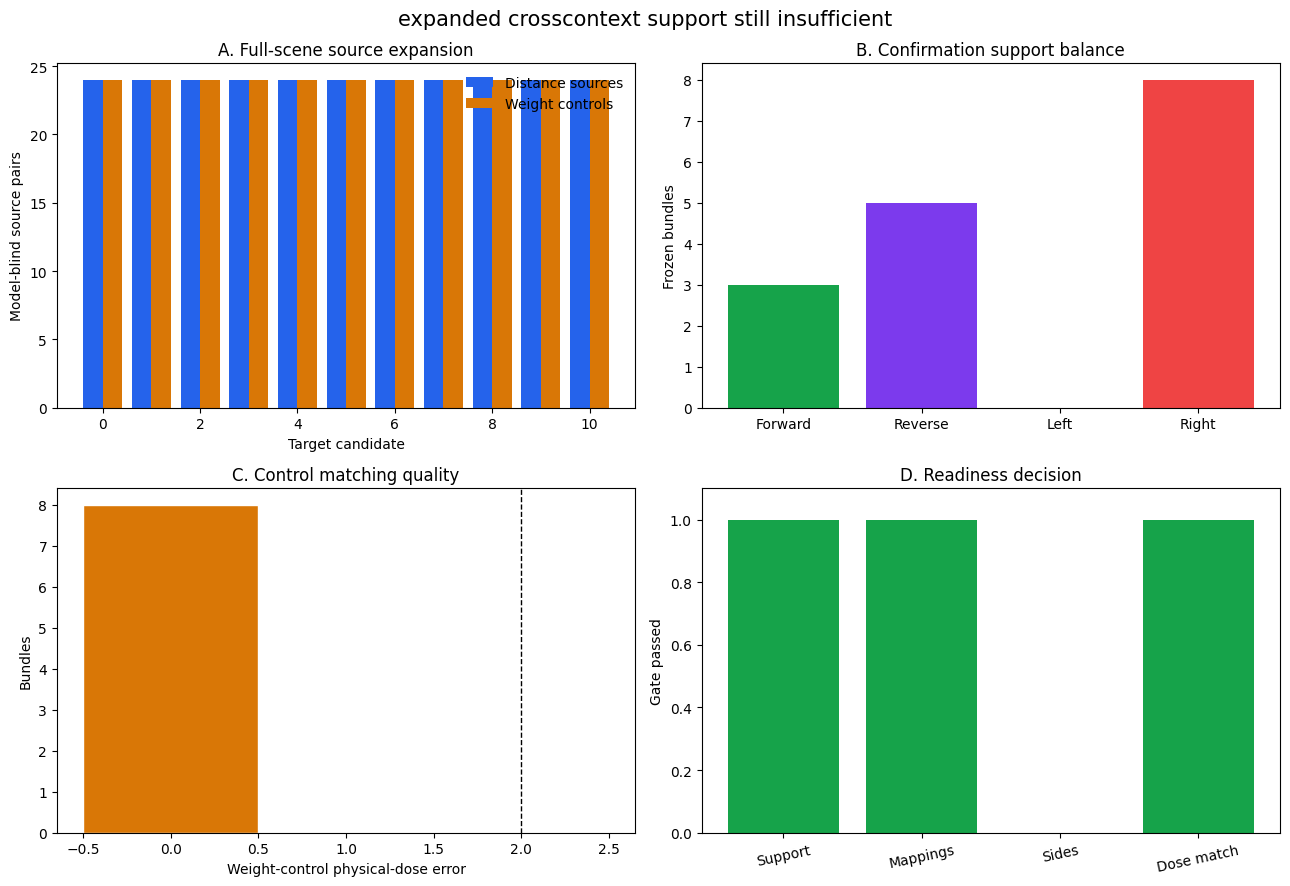

Saved: /content/drive/MyDrive/VisualTorque/results/qwen27b_expanded_crosscontext_source_readiness_v1/analysis/figures/expanded_crosscontext_readiness.png


In [15]:
%%cell_progress 14/15 Save the paper-facing readiness figure
cell_stage('Rendering candidate expansion, balance, and dose matching')
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

candidate_counts = pd.DataFrame([{
    'pair_id': row['pair_id'],
    'distance': len(row['distance_candidates']),
    'weight': len(row['weight_candidates']),
} for row in expanded_pool])
x = np.arange(len(candidate_counts))
axes[0, 0].bar(x - 0.2, candidate_counts['distance'], 0.4,
               label='Distance sources', color='#2563EB')
axes[0, 0].bar(x + 0.2, candidate_counts['weight'], 0.4,
               label='Weight controls', color='#D97706')
axes[0, 0].set_xlabel('Target candidate')
axes[0, 0].set_ylabel('Model-blind source pairs')
axes[0, 0].set_title('A. Full-scene source expansion')
axes[0, 0].legend(frameon=False)

labels = ['Forward', 'Reverse', 'Left', 'Right']
values = [
    mapping_counts.get('forward', 0), mapping_counts.get('reverse', 0),
    side_counts.get('left', 0), side_counts.get('right', 0),
]
axes[0, 1].bar(np.arange(4), values,
               color=['#16A34A', '#7C3AED', '#0EA5E9', '#EF4444'])
axes[0, 1].set_xticks(np.arange(4), labels)
axes[0, 1].set_ylabel('Frozen bundles')
axes[0, 1].set_title('B. Confirmation support balance')

if len(coverage_frame):
    axes[1, 0].hist(
        coverage_frame['weight_dose_match_error'],
        bins=np.arange(-0.5, MAX_WEIGHT_DOSE_ERROR + 1.5, 1),
        color='#D97706', edgecolor='white',
    )
axes[1, 0].axvline(
    MAX_WEIGHT_DOSE_ERROR, color='black', linestyle='--', linewidth=1
)
axes[1, 0].set_xlabel('Weight-control physical-dose error')
axes[1, 0].set_ylabel('Bundles')
axes[1, 0].set_title('C. Control matching quality')

gate_labels = [
    'Support', 'Mappings', 'Sides', 'Dose match'
]
gate_values = [int(value) for value in READINESS_GATES.values()]
axes[1, 1].bar(
    np.arange(len(gate_values)), gate_values,
    color=['#16A34A' if value else '#DC2626' for value in gate_values],
)
axes[1, 1].set_xticks(
    np.arange(len(gate_values)), gate_labels, rotation=12
)
axes[1, 1].set_ylim(0, 1.1)
axes[1, 1].set_ylabel('Gate passed')
axes[1, 1].set_title('D. Readiness decision')

fig.suptitle(PRIMARY_DECISION.replace('_', ' '), fontsize=15)
fig.tight_layout()
figure_path = FIGURE_DIR / 'expanded_crosscontext_readiness.png'
fig.savefig(figure_path, dpi=220, bbox_inches='tight')
plt.show()
print('Saved:', figure_path)


In [16]:
%%cell_progress 15/15 Write the expanded-readiness report
cell_stage('Saving the report and completion manifest')

serializable_gates = {
    key: bool(value) for key, value in READINESS_GATES.items()
}
lines = [
    '# Expanded Cross-Context Source Readiness', '',
    f"**Primary decision:** `{PRIMARY_DECISION}`", '',
    '## Support', '',
    f"- Prior-screen target candidates: {len(target_pool)}",
    f"- Batch-one behavior requests: {len(screen_records)}",
    f"- Targets with valid source pairs: {len(eligible)}",
    f"- Frozen scene-disjoint bundles: {len(confirmation_manifest)}",
    f"- Mapping counts: `{json.dumps(dict(mapping_counts), sort_keys=True)}`",
    f"- Changed-side counts: `{json.dumps(dict(side_counts), sort_keys=True)}`",
    f"- Readiness gates: `{json.dumps(serializable_gates, sort_keys=True)}`",
    '', '## Interpretation', '',
    (
        'Passing authorizes the unchanged correct-source intervention on the '
        'frozen manifest. Failure is a behavioral-support result and does not '
        'authorize activation analysis or a mechanism conclusion.'
    ), '',
]
report_path = ANALYSIS_DIR / 'EXPANDED_CROSSCONTEXT_READINESS_REPORT.md'
report_path.write_text('\n'.join(lines) + '\n', encoding='utf-8')

completion = {
    'schema_version': 'expanded-crosscontext-readiness-complete-1.0',
    'completed_at_utc': datetime.now(timezone.utc).isoformat(),
    'model_id': MODEL_ID,
    'revision': MODEL_REVISION,
    'primary_decision': PRIMARY_DECISION,
    'readiness_passed': READINESS_PASSED,
    'readiness_gates': serializable_gates,
    'bundle_count': len(confirmation_manifest),
    'manifest_path': str(MANIFEST_PATH),
    'report_path': str(report_path),
    'figure_path': str(figure_path),
    'protocol_sha256': sha256_file(PROTOCOL_LOCK_PATH),
    'pool_sha256': sha256_file(SOURCE_POOL_PATH),
    'screen_sha256': sha256_file(SCREEN_RESULT_PATH),
    'manifest_sha256': sha256_file(MANIFEST_PATH),
}
write_json_atomic(OUTPUT_ROOT / 'RUN_COMPLETE.json', completion)
print('Primary decision:', PRIMARY_DECISION)
print('Report:', report_path)
print('Run complete:', OUTPUT_ROOT / 'RUN_COMPLETE.json')


Write the expanded-readiness report:  93%|#########3| 14/15 [00:00<?, ?cell/s]

Primary decision: expanded_crosscontext_support_still_insufficient
Report: /content/drive/MyDrive/VisualTorque/results/qwen27b_expanded_crosscontext_source_readiness_v1/analysis/EXPANDED_CROSSCONTEXT_READINESS_REPORT.md
Run complete: /content/drive/MyDrive/VisualTorque/results/qwen27b_expanded_crosscontext_source_readiness_v1/RUN_COMPLETE.json
